# Machine Learning - Practical 2 - Introduction to PyTorch and Linear Regression with PyTorch

**Authors:** Muhammed Nagaş, Felix Fischer, Niclas Langer  
Summer term 2026

*Machine Learning course, University of Göttingen, summer term 2026. The exercise template (task text, helper code) was provided by the course; the solutions and answers are ours.*

# Introduction

In this task, you will get to know the basic tools used by the machine learning community. Later, we will build a linear regression model with PyTorch.

**Why PyTorch for Linear Regression?**

You might wonder why we are using PyTorch to solve a simple linear problem.
Linear Regression is the most basic form of a neural network. In PyTorch, we treat a linear model as a single-neuron network. By learning the PyTorch workflow now (DataLoaders, Optimizers, and the Training Loop), you are building the foundation for the next practical. Once you understand how to "train" a simple model, moving to complex deep learning models later is simply a matter of adding more layers!

## Tutorials

Some python libraries are required to accomplish the tasks assigned in this homework. If you feel like you need to follow a tutorial before, feel free to do so:

*   [PyTorch Tutorial](https://pytorch.org/tutorials/)
*   [Seaborn Tutorial](https://seaborn.pydata.org/tutorial.html) (data visualization library on top of matplotlib)


In [1]:
import random
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import torch
import pathlib
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from torch.utils.data import sampler

In [2]:
torch.set_default_dtype(torch.float64)

## System checks

Perform some rudimentary system checks. Do we have a CUDA-capable device? Multiple? Is CuDNN active (huge speedups for some networks)?

In [3]:
torch.cuda.is_available(), torch.backends.cudnn.is_available(), torch.cuda.device_count()

(False, True, 0)

If you see now that now that there is no CUDA-capable device available, you have to activate the GPU.

On on a notebook at kaggle.com scroll on the right hand side to "Session options" and set one of the listed GPUs there.

Alternatively you could for example also use google colab or you own personal GPU


Now check the availability again (after re-running the imports)

In [4]:
print(torch.cuda.is_available(), torch.backends.cudnn.is_available(), torch.cuda.device_count())
try:
    print(torch.cuda.current_device())
except Exception as e:
    print("Error:", e)

False True 0
Error: Found no NVIDIA driver on your system. Please check that you have an NVIDIA GPU and installed a driver from http://www.nvidia.com/Download/index.aspx


Choose your device for computation. CPU or one of your CUDA devices?

In [5]:
# DO NOT CHANGE
use_cuda = True
#use_cuda = False
use_cuda = False if not use_cuda else torch.cuda.is_available()
device = torch.device('cuda:0' if use_cuda else 'cpu')
torch.cuda.get_device_name(device) if use_cuda else 'cpu'
print('Using device', device)

Using device cpu


# PyTorch: Getting to know Tensors

*feel free to skip this before 'Machine Learning with Pytorch' section if you feel confident enough*   
PyTorch is a library for machine learning on arbitrary datasets, including irregular input data such as graphs, point clouds and manifolds.

In this short tutorial we will explore some of its features to handle data in tensors.
If you want, you can look into more [detailed PyTorch tutorials](https://pytorch.org/tutorials/) online.

In [6]:
# create a numpy array
numpyarray = np.arange(10).reshape(2, 5)
# convert to pytorch tensor
a = torch.from_numpy(numpyarray)

Let us find out what the properties of this tensor 'a' are.

In [7]:
# TODO print the tensor
print(a)

tensor([[0, 1, 2, 3, 4],
        [5, 6, 7, 8, 9]])


In [8]:
# TODO print its type
print(a.dtype)

torch.int64


In [9]:
# TODO print its shape
print(a.shape)

torch.Size([2, 5])


In [10]:
# TODO print its size
print(a.size())

torch.Size([2, 5])


In [11]:
# TODO create a new numpy array out of the tensor and print its size
b = a.numpy()
print(b.size)

10


Let's create some new tensors.

In [12]:
# TODO create a tensor of shape (2,5) filled with ones of type int and print it
t1 = torch.ones((2, 5), dtype=torch.int64)
print(t1)

tensor([[1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1]])


In [13]:
# TODO create a tensor of shape (3,4) filled with zeros and print it
t2 = torch.zeros((3, 4))
print(t2)

tensor([[0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.]])


In [14]:
# TODO transpose the tensor 'a'
a.transpose(0, 1)

tensor([[0, 5],
        [1, 6],
        [2, 7],
        [3, 8],
        [4, 9]])

Now change a value in the numpy array. Does the corresponding tensor change?

In [15]:
# TODO change value in numpy array and inspect the tensor a
b[0, 0] = 100
print(a[0, 0])

tensor(100)


**Yes** 

Does it work the other way round as well?

In [16]:
a[0, 0] = 0
print(b[0, 0])

0


**Yes** 

Now we want to make use of the different devices available, namely cpu and gpu.

In [17]:
# TODO move 'a' to the gpu
a.to(device)

tensor([[0, 1, 2, 3, 4],
        [5, 6, 7, 8, 9]])

If you change a value in the tensor 'a' now, does the corresponding value in the tensor on the GPU change as well?

**No.** `a.to(device)` returns a *new* tensor that lives in GPU memory (a copy), so later changes to `a` on the CPU are not reflected in it. (If no GPU is available, `.to('cpu')` simply returns `a` itself.)


# Machine Learning with PyTorch

Whether you are training a simple linear model or a 100-layer neural network, the PyTorch "blueprint" remains the same.

### 1. Data Loading and Preprocessing
Everything begins with data. We have to choose a dataset and split it into three distinct sets:
* **Training set:** Used by the model to learn the underlying patterns.
* **Validation set:** Used to monitor progress and tune settings during training without "polluting" the model with the test data.
* **Test set:** Held back until the very end to evaluate how the model performs on completely unseen data.

Since real-world data is often messy, we use a `Dataset` or `DataLoader` to handle preprocessing, such as **normalization**, which ensures our input features are on a similar scale.

### 2. Specify the Model, Loss, and Optimizer
Next, we define the mathematical structure of our model. In this notebook, our model represents the linear equation:
$$y = Xw + b$$

In PyTorch terminology, this is often called a **Linear Layer** or a **Fully-Connected Layer**.

We also choose a **Loss Function** (to measure how wrong we are) and an **Optimizer** (the strategy for updating our weights). A key setting here is the **Learning Rate**, which determines the size of the "steps" we take toward the best solution.

### 3. Model Fitting (The Training Loop)
The "fitting" process is a cycle repeated for a set number of **Epochs**. Each cycle consists of:
* **Forward Pass:** The data is fed through the model to produce a prediction.
* **Loss Calculation:** We compare the prediction to the actual "ground truth" value.
* **Backward Pass (Backpropagation):** We calculate the **gradient** (direction and magnitude of error) for each parameter.
* **Update:** The optimizer adjusts the weights slightly to reduce the loss.

During this process, we periodically compute the loss on the **validation set**. This helps us detect **overfitting**, which occurs when a model memorizes the training data but fails to generalize to new information. 

After training is complete, we perform one final evaluation on the **test set** to see our model's true performance.

## Data Loading and Preprocessing

### Training, Validation and Test Sets

For the correct fitting of a machine learning model we need three dataset components: one for training, one for validation in the training process, and the last one for testing the results of the training on unseen data.

Note that you should not use the test set in any part of your training and model selection procedure. It should be only used for showing the final results.  

Usually, train and test datasets are already split in the provided kaggle datasets but as we work with a custom dataset, we would have to make train-test split ourselves first.

In [18]:
from sklearn.model_selection import train_test_split

In [19]:
test_size = 0.2
target_clm='critical_temp'

In [20]:
# TODO: load data - same as in the previous practical and make train_test_split from sklearn

data = pd.read_csv('../data/superconduct_train.csv')
train, test = train_test_split(data, test_size=test_size, random_state=42)

### Dataset

PyTorch has 2 entities to load data. They are **Dataset** and **Dataloader**.
**Dataset** is a class, which defines your data and often applies data preprocessing transformations, like normalization. It should have at least 3 functions :
* __init__ - as any other init. Usually, you would provide path to dataset here or dataset elements.
* __len__ - should return the whole dataset size
* __getitem__ - this function returns 1 pair of data and label, also here preprocessing transformations are usually applied



For the next exercise, take a look here for an example https://stanford.edu/~shervine/blog/pytorch-how-to-generate-data-parallel

In [21]:
class Dataset(torch.utils.data.Dataset):
    def __init__(self, df, target_clm, mean=None, std=None, normalise=True):
        '''
        TODO: save params to self attributes,
        x is data without target column
        y is target column
        transform df to_numpy
        '''
        self.x = df.drop(columns=[target_clm]).to_numpy()
        self.y = df[target_clm].to_numpy()
        self.mean = mean
        self.std = std
        self.normalise = normalise

    def __len__(self):
        # TODO: return whole dataset length
        return self.x.shape[0]
        
    def __getitem__(self, index):
        # TODO: return x and y for the given index, if normalise is True, normalise x using mean and std of the training set
        x = self.x[index]
        y = self.y[index]
        if self.normalise:
            x = (x - self.mean) / self.std
        return x, torch.tensor([y])  # wrap y in tensor to get correct dimensions from dataloader later
        

In [22]:
tmp_dataset = Dataset(train, target_clm, normalise=False)

In [23]:
# TODO calculate the mean and standard deviation of the train dataset
X_train = train.drop(columns=[target_clm])
X_train_mean = np.mean(X_train, axis=0).to_numpy()
X_train_std = np.std(X_train, axis=0).to_numpy()

In [24]:
# TODO define new datasets with mean, std and normalise=True
conductor_train = Dataset(train, target_clm, mean=X_train_mean, std=X_train_std, normalise=True)
conductor_test = Dataset(test, target_clm, mean=X_train_mean, std=X_train_std, normalise=True)

We need to **split** the train dataset in two sets, one for training and one for validation.
While the training set needs to be quite large, the validation set can be relatively small.
Take 10 % of the dataset as validation set.
Assign samples *randomly* to the training and validation set, using a fixed seed to ensure that train and test splits are same across different model runs.

In fact, the good practice is to fix a global random seed not only the generator seed for even better reproducibility with `torch.manual_seed(0)`.
Machine learning models often involve random initialization of weights, augmentations, dropout layers, and other stochastic processes. Without fixing the random seed, each run of the model may produce slightly different results, making it challenging to reproduce specific results or debug issues.

In [25]:
# TODO split the train dataset in conductor_train and conductor_val
torch.manual_seed(0)
# split the *training* part (not the whole data set) so the test set stays unseen
train, val = train_test_split(train, test_size=0.1, random_state=0)
conductor_train = Dataset(train, target_clm, mean=X_train_mean, std=X_train_std, normalise=True)
conductor_val = Dataset(val, target_clm, mean=X_train_mean, std=X_train_std, normalise=True)

In [26]:
batch_size = 256

To load the data for model training, we need to define the **dataloaders**.
A dataloader represents a Python iterable over a dataset and draws mini batches with random samples.
**Dataloader** calls \_\_getitem__ function from the Dataset and forms the batches.


Use the batch size as specified above.
Make sure we get shuffled samples in batches.

In [27]:
# TODO create dataloader for training, validation and test
train_dataloader = DataLoader(conductor_train, batch_size=batch_size, shuffle=True)
val_dataloader = DataLoader(conductor_val, batch_size=batch_size, shuffle=True)
test_dataloader = DataLoader(conductor_test, batch_size=batch_size, shuffle=True)

Let's get a data point now to see what we're dealing with.

For this, you might want to check out how python's iterator protocol works. It's simple and will give you an important insight into python: https://wiki.python.org/moin/Iterator.

In [28]:
# TODO get an element of the train_dataloader
batch = next(iter(train_dataloader))

In [29]:
# TODO print the dimensions of for elements from the previous step
for t in batch:
    print(t.shape)

torch.Size([256, 81])
torch.Size([256, 1])


x has size (\[batchsize\], 81) --> 256 elements/batches (or whatever you have defined in your data loader), 81 feature values.

y has size (\[batchsize\], 1) --> 256 elements/batches (again depends on your data loader config). There's one target value for each set of the features.

## Specify Model & Optimizer

### Specify a Model

The task is now to define a model to train on the data. In this simple example, we only need Linear Layer (often called a "fully-connected" layer in neural network contexts) as defined in *torch.nn.Linear* that produces a predicted label for a specific training input row.

Before, we set some variables:
- the input and output size of the linear layer
- how long we want to train the model (number of epochs) and
- the learning rate.


In [30]:
epochs = 1
input_dim = 81
output_dim = 1
lr = 0.001

In [31]:
class LinearRegression(torch.nn.Module):
    """
    Linear regression model inherits the torch.nn.Module
    which is the base class for all PyTorch modules.
    """
    def __init__(self, input_dim, output_dim):
        """ Initializes internal Module state. """
        super(LinearRegression, self).__init__()
        # TODO: define a linear layer for the model using torch.nn.Linear
        self.flatten = torch.nn.Flatten()
        self.linear = torch.nn.Linear(input_dim, output_dim)
        

    def forward(self, x):
        """ Defines the computation performed at every call. """
        # TODO: flatten the input to a suitable size for the linear layer 
        # Hint: use x.reshape(...) and the input_dim variable
        x = self.flatten(x)
        
        # TODO: run the flattened data through the linear layer and return the outputs
        return self.linear(x)

### Instantiate the Model

Let us instantiate the model and take a look at the inside. It is always a good idea to verify that the actual architecture is what you intended it to be. Especially, when you start to create layers dynamically it is great for inspection/verification/debugging.

In [32]:
# TODO instantiate the model
model = LinearRegression(input_dim, output_dim)

Feed the model to the GPU if available.

In [33]:
# TODO move model to device you specified above
model.to(device)

LinearRegression(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear): Linear(in_features=81, out_features=1, bias=True)
)

Put the model in training mode.

In [34]:
# TODO put the model in train mode
model.train()

LinearRegression(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear): Linear(in_features=81, out_features=1, bias=True)
)

### Define a Loss Function

Since we're dealing with regression problem, [MSELoss](https://pytorch.org/docs/stable/generated/torch.nn.MSELoss.html) is the canonical choice for the loss.

In [35]:
# TODO define the loss function
loss_function = torch.nn.MSELoss()

## Model Fitting

### Train the Model

Everything is set for the model to train!

- In the forward pass, the prediction is made using the previously defined model on the elements of the dataloader.
- Then the loss (or error) needs to be computed by comparing the prediction to the actual label.
- In the backward pass, the model learns and updates its weights based on the current gradient.

### First, let's do all of the steps manually, without using the optimizer

**Hints:**
* define number of epochs to see the dynamic. You need to see the effect over several epochs but it should no be too long. 
* use learning rate defined above as `lr`
* when doing parameters update - do it under `with torch.no_grad():`. This would disable the gradient computation for the operations under it. And we don't need gradients for updating the weights step.
* you need to update the model parameters. See [here](https://pytorch.org/tutorials/beginner/introyt/modelsyt_tutorial.html) for more details on how to access them
* don't forget to track the learning (loss)
* even though you should not use a preimplemented optimizer here you are allowed to call `loss.backward()` to compute the individual gradients

In [36]:
## TODO do a simple for-loop to illustrate how the gradient update if done over batches. 
## Print loss values across epochs to compare with the PyTorch optimizers later
epochs = 10
for epoch in range(1, epochs + 1):
    last_loss = None
    for batch, (X, y) in enumerate(train_dataloader):
        y_pred = model(X)
        loss = loss_function(y_pred, y)
        last_loss = loss.item()
        loss.backward()
        with torch.no_grad():
            for param in model.parameters():
                param.subtract_(param.grad, alpha=lr)  # subtract_ -> in-place
                param.grad.zero_()  # reset, otherwise gradients accumulate over batches
    print(f"{epoch=}, loss={last_loss}")

epoch=1, loss=1427.9843810465386


epoch=2, loss=1240.4978260997716


epoch=3, loss=1226.5098375375037


epoch=4, loss=959.2381635102629


epoch=5, loss=815.9128539827627


epoch=6, loss=696.3501488069313


epoch=7, loss=774.787084264611


epoch=8, loss=630.8257744984415


epoch=9, loss=623.7811799071225


epoch=10, loss=506.67516537796587


This was equivalent to SGD optimizer

### Now let's do it in the pytorch style using the optimizer  

The optimizer is the learning algorithm we use. In this case, we use Stochastic Gradient Descent (SGD).
Redefine the model and initialize SGD optimizer

In [37]:
# TODO Redefine the model and initialize SGD optimizer, write a train loop as above and compare the loss values
model = LinearRegression(input_dim, output_dim)
model.to(device)
model.train()
loss_function = torch.nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=lr)

epochs = 15
for epoch in range(1, epochs + 1):
    last_loss = None
    for batch, (X, y) in enumerate(train_dataloader):
        y_pred = model(X)
        loss = loss_function(y_pred, y)
        last_loss = loss.item()
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

    print(f"{epoch=}, loss={last_loss}")

epoch=1, loss=1585.6949873814144


epoch=2, loss=1204.3668274888412


epoch=3, loss=1138.7210591580817


epoch=4, loss=944.0248781537243


epoch=5, loss=867.189338789455


...

epoch=11, loss=436.2572553995597


epoch=12, loss=528.1921875146005


epoch=13, loss=473.2812394453099


epoch=14, loss=475.7629057283347


epoch=15, loss=432.7158547911846


### Make a Prediction

Now that our model is trained, we can make a new prediction by inputting an unseen data row from the test dataset.

Run this cell several times, does the model predict accurately?

Set the number of epochs to 15 during training and try again!

**TODO your answer here** - With one epoch of training, the prediction is not really accurate. With 15 epochs, the prediction is not perfect but much more accurate.

In [38]:
# TODO get a random element of the test dataloader
X, y = next(iter(test_dataloader))
X = X[:1]
y = y[:1]

# TODO make a prediction
model.eval()
y_pred = model(X)

# print predicted label and given label
print(f"pred: {y_pred}, true: {y}")

pred: tensor([[16.9586]], grad_fn=<AddmmBackward0>), true: tensor([[22.]])


### Track and Plot the Training and Validation error

What we have seen so far is the basic principle of training a model and making a prediction. But one might be interesting to see more about the training process, for instance how the training error evolves with time.

For this step, we are going to **refine the training process** and **add some important information saving for plotting**.

Create a plot using **seaborn** that contains both the losses on training set and the losses on the validation set for each epoch.




**Note:** Do not forget to add title, axis labels and a legend!
This applies in general, please keep in mind for future exercise sheets.

In [39]:
# TODO refine the training function from above
# it should contain:
# - saving of losses
# - returning the mean loss

def train_model(model, loss_function, dataloader, optimizer):
    model.train()
    losses = []
    for batch, (X, y) in enumerate(dataloader):
        y_pred = model(X)
        loss = loss_function(y_pred, y)
        losses.append(loss.item())
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()
    return sum(losses) / len(losses)

In [40]:
# TODO write a validation function that calculates the loss on the validation set
# you can also combine it with the training function

def validate_model(model, loss_function, dataloader):
    model.eval()
    losses = []
    with torch.no_grad():  # no gradients needed for validation
        for batch, (X, y) in enumerate(dataloader):
            y_pred = model(X)
            loss = loss_function(y_pred, y)
            losses.append(loss.item())
    return sum(losses) / len(losses)

In [41]:
# TODO write a run_training function that
# - calls the train and validate functions for each epoch
# - saves the train_losses, val_losses as arrays for each epoch

def run_training(model, epochs, learning_rate):
    loss_train = np.empty(epochs)
    loss_val = np.empty(epochs)
    
    loss_function = torch.nn.MSELoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
    for epoch in range(epochs):
        loss_train[epoch] = train_model(model, loss_function, train_dataloader, optimizer)
        loss_val[epoch] = validate_model(model, loss_function, val_dataloader)

    return pd.DataFrame({"epoch": np.arange(1, epochs + 1), "loss_train": loss_train, "loss_val": loss_val})

In [42]:
# TODO call the run_training function and run it for 10 epochs.
num_epochs = 15
model = LinearRegression(input_dim, output_dim)
model.to(device)
df_losses = run_training(model, num_epochs, lr)

In [43]:
# TODO write a plot function
def plot():
    sns.set_theme()

    # Convert from wide to long format
    df_long = df_losses.melt(
        id_vars="epoch",
        var_name="type",
        value_name="loss"
    )
    #print(df_long)
    
    sns.lineplot(data=df_long, x="epoch", y="loss", hue="type")
    plt.title("Epoch vs. Loss")

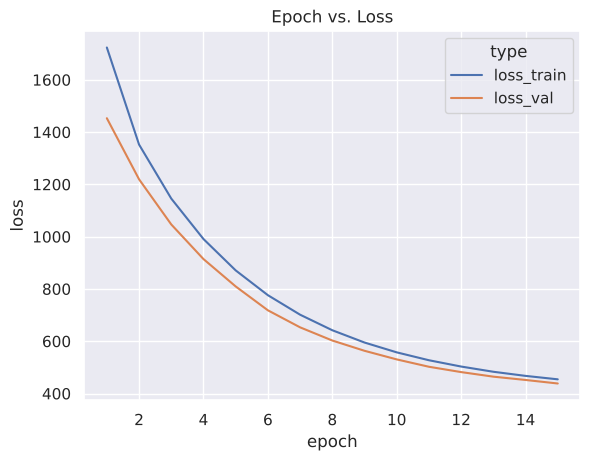

In [44]:
# TODO plot losses
plot()

Comment on the loss curve. Does it look as expected? Why/Why not?
If not, what might be the reason.

Answer: Unexpectedly, the validation loss is lower than the training loss. This is probably due to the validation happening after an entire epoch has finished while the training loss gets calculated from values throughout the epoch.

# Hyperparameters influence

Now, once we successfully reproduced linear regression using PyTorch, lets explore the hyperparameters influence, such as learning rate or batch size.

Train several models with 30 train epochs and using different learning rates - [0.0001, 0.001, 0.01, 0.1, 1, 10].
What do you notice? Why?

*Hints*: 
* Do not forget to reinitialize models and update the optimizers
* Use different colors and line styles to display different learning rates and train-validation splits

In [45]:
num_epochs = 30
## TODO - train models with different learning rates

df_losses = pd.DataFrame()

for i_model, lr in enumerate([0.0001, 0.001, 0.01, 0.1, 1, 10]):
    print(f"Training model {i_model} with learning rate {lr} ...")
    model = LinearRegression(input_dim, output_dim)
    model.to(device)
    df = run_training(model, num_epochs, lr)

    df_long = df.melt(
        id_vars="epoch",
        var_name="type",
        value_name="loss"
    )
    df_long["lr"] = lr

    df_losses = pd.concat((df_losses, df_long), ignore_index=True)  # ignore_index -> no duplicated index values

Training model 0 with learning rate 0.0001 ...


Training model 1 with learning rate 0.001 ...


Training model 2 with learning rate 0.01 ...


Training model 3 with learning rate 0.1 ...


Training model 4 with learning rate 1 ...


Training model 5 with learning rate 10 ...


Text(0.5, 1.0, 'Epoch vs. Loss (all learning rates)')

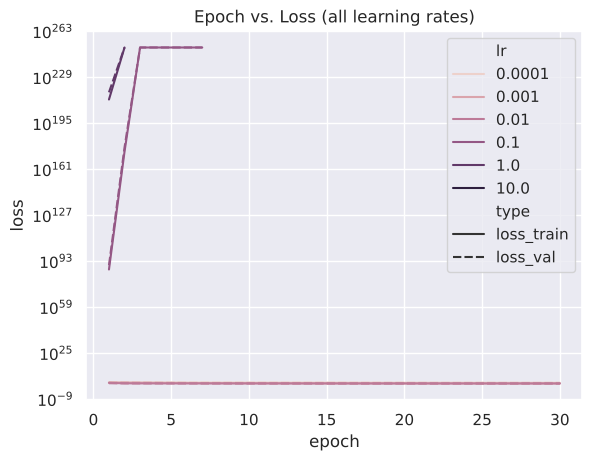

In [46]:
## TODO plot the losses from different models. What do you see and why?

df_filtered = df_losses.copy()
df_filtered["loss"] = df_filtered["loss"].clip(upper=10.0e250)  # removing infinites wasn't enough to get seaborn to work

#normalize = sns.object.Norm(func=lambda h: np.log10(h*10**4))
lp = sns.lineplot(data=df_filtered, x="epoch", y="loss", hue="lr", style="type", hue_norm=mpl.colors.LogNorm())
lp.set(yscale="log")
plt.title("Epoch vs. Loss (all learning rates)")

Text(0.5, 1.0, 'Epoch vs. Loss (lowest three learning rates)')

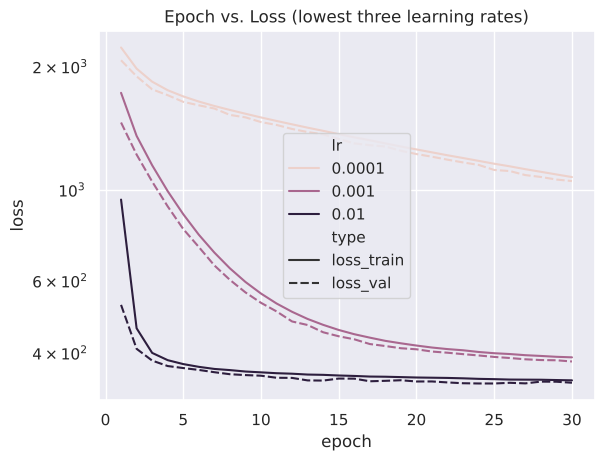

In [47]:
df_filtered = df_filtered[df_filtered["lr"] <= 0.01]
lp = sns.lineplot(data=df_filtered, x="epoch", y="loss", hue="lr", style="type", hue_norm=mpl.colors.LogNorm())
lp.set(yscale="log")
plt.title("Epoch vs. Loss (lowest three learning rates)")

## How do we know the amount of epochs and best learning rates?

The honest answer - we just try it out. The heuristics, which are typically used are the following
* use adaptive optimizers. Adam would be a typical example. It is an adaptive learning rate optimization algorithm that is designed to be appropriate for non-stationary objectives and problems with very noisy and/or sparse gradients. More details [here](https://paperswithcode.com/method/adam). This makes the training more robust to the choise of the the learning rate
* Use schedulers for the training. They change the value of the learning rate based on the loss behaviour. The most typical ones are
  * Early stopper . The early stopper is helpful to avoid redundunt computations and overfitting. It basically stops the train loop if the loss function does not decrease on the validation split for some time.
  * Warm up. Warm up slowly increases the learning rate in the begining of the training. This helps to avoid bad influence of not-so-good initialisation and especially helpful for the layers, which need to accumulate statistics, such as BatchNorm. We will use such layers later in the course.

### Task
Modify the the training function with the early stopper logic.
This should stop the training loop if the validation loss function does not have a relevant improvement over $N$ epochs. The improvement is only something, which is better than the $tol$ value, which stays for the tolerance.

Use $tol=2$, $N=5$, $num\_epochs=150$, $lr=0.01$ for the function start.

**Question**:
* Can $tol=0$? Why?
    * It could, but it would effectively turn off early stopping.
* How many epochs it would really run? Try to change the $lr=0.001$ and $lr=0.0001$ and see when this would stop.
    * For lr=0.01 it stopped after 23 epochs, for lr=0.001 after 44 epochs, and for lr=0.0001 it did not stop before reaching the limit of 150 epochs.
* What happens if you increase the tolerance?
    * Then learning is potentially stopped sooner.
* What if you increase $N$?
    * Then learning is potentially stopped later.

In [48]:
## TODO: adopt the train function with the early stopper logic

def run_training_early_stopping(model, num_epochs, learning_rate, tol, N):
    loss_function = torch.nn.MSELoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)

    train_losses = []
    val_losses = []

    best_val_loss = float("inf")
    epochs_without_improvement = 0

    for epoch in range(num_epochs):
        train_loss = train_model(model, loss_function, train_dataloader, optimizer)
        val_loss = validate_model(model, loss_function, val_dataloader)

        train_losses.append(train_loss)
        val_losses.append(val_loss)

        # Early stopping
        if best_val_loss - val_loss > tol:
            best_val_loss = val_loss
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= N:
            print(f"Early stopping at epoch {epoch + 1}")
            break

    return pd.DataFrame({
        "epoch": np.arange(1, len(train_losses) + 1),
        "loss_train": train_losses,
        "loss_val": val_losses,
    })

In [49]:
## TODO: Train models with early stopping with the different learning rates

num_epochs = 150
learning_rates = [0.01, 0.001, 0.0001]

loss_early_stop = pd.DataFrame()

for lr in learning_rates:
    print(f"Training with learning rate {lr} ...")

    model = LinearRegression(input_dim, output_dim)
    model.to(device)

    df = run_training_early_stopping(model, num_epochs, lr, tol=2, N=5)

    df_long = df.melt(
        id_vars="epoch",
        var_name="type",
        value_name="loss"
    )
    df_long["lr"] = lr
    
    loss_early_stop = pd.concat([loss_early_stop, df_long], ignore_index=True)

Training with learning rate 0.01 ...


Early stopping at epoch 23
Training with learning rate 0.001 ...


Early stopping at epoch 44
Training with learning rate 0.0001 ...


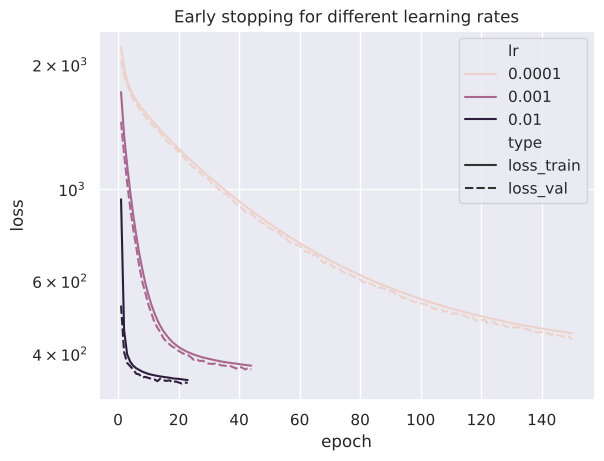

In [50]:
## TODO: Visualize the results. What do you see and why?

sns.set_theme()

lp = sns.lineplot(
    data=loss_early_stop,
    x="epoch",
    y="loss",
    hue="lr",
    style="type",
    hue_norm=mpl.colors.LogNorm()
)

lp.set(yscale="log")
plt.title("Early stopping for different learning rates")
plt.show()

Oberservation: The learning stops at different epochs and at different losses. For lr=0.0001 we got the longest runtime but also the worst loss because it didn't improve fast enough to prevent triggering the early stopping.

## Now lets try to explore the impact of the batch size

**Task:** Fix $num\_epochs = 150$ and $lr = 0.001$ and try to change the batch size using values $[4, 32, 128, 1024]$ for the batch size.
* What impact the batch size have? Why?

In [51]:
num_epochs = 150
lr = 0.001
## TODO: Train with different batch sizes

df_batch_losses = pd.DataFrame()

for batch_size in [4, 32, 128, 1024]:
    print(f"Training model with batch size {batch_size} ...")

    train_dataloader = DataLoader(conductor_train, batch_size=batch_size, shuffle=True)
    val_dataloader = DataLoader(conductor_val, batch_size=batch_size, shuffle=True)

    model = LinearRegression(input_dim, output_dim)
    model.to(device)

    df = run_training_early_stopping(model, num_epochs, lr, tol=2, N=5)

    df_long = df.melt(
        id_vars="epoch",
        var_name="type",
        value_name="loss"
    )
    df_long["batch_size"] = batch_size

    df_batch_losses = pd.concat([df_batch_losses, df_long], ignore_index=True)

Training model with batch size 4 ...


Early stopping at epoch 19
Training model with batch size 32 ...


Early stopping at epoch 21
Training model with batch size 128 ...


Early stopping at epoch 28
Training model with batch size 1024 ...


Early stopping at epoch 65


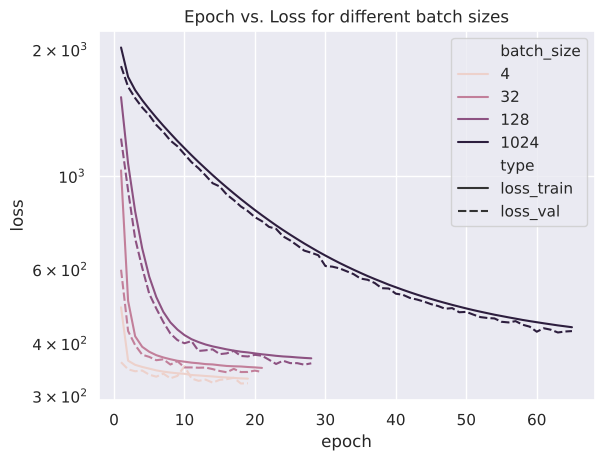

In [52]:
## TODO: Visualize the differences 

lp = sns.lineplot(
    data=df_batch_losses,
    x="epoch",
    y="loss",
    hue="batch_size",
    style="type",
    hue_norm=mpl.colors.LogNorm()
)
lp.set(yscale="log")
plt.title("Epoch vs. Loss for different batch sizes")
plt.show()

Observation:
Smaller batch sizes converge faster in terms of epochs, probably because new information is being used sooner to update the parameters. However, it seems that smaller batch size are slower to computer, which makes it unclear whether they are really faster.